# Semana 14 · PCA y evaluación de mejoras al modelo
### Cuaderno de Santi · Estudiante ID 24 · Data Analytics ML Challenge 2026-2

| Ficha | |
|---|---|
| Estudiante | David Santiago Pedraza Ochoa (Santi) |
| ID / semilla | **24** / `1024` |
| Huella de la muestra (semana 12) | `89a094b75572` |
| Caso | Brazilian E-Commerce Public Dataset by Olist: ¿llega tarde el pedido? |
| Profesor | Elias Buitrago Bolivar · Universidad Central |
| Muestra | 35.000 pedidos: 24.500 entrenamiento · 5.250 validación · 5.250 prueba (sin usar) |

## Resumen ejecutivo

| Pregunta | Respuesta con mi muestra (ID 24) |
|---|---|
| ¿Cuántas componentes hacen falta para el 90 %? | **15** de 24 variables numéricas (90.76 % de varianza) |
| ¿Cuál de las cuatro versiones elijo? | **A** (sin PCA, C = 1.0): Recall 0.665, F1 0.213, costo R$ 17.205 |
| ¿PCA o cambiar `C` mejoraron el modelo? | **No.** PCA empeoró todas las métricas; `C` movió muy poco los resultados |
| ¿Conviene usarlo como alerta automática? | **No** con estos costos: cuesta R$ 4.780 más que no alertar (R$ 12.425) |
| ¿Cambia `valor_flete` entre entrenamiento y validación? | **No hay evidencia** (KS: D = 0.0122, p = 0.533) |

Todo se midió en validación; la prueba final sigue reservada.

## Cómo leer este cuaderno

Está organizado por preguntas, no por pasos técnicos. Cada **tabla** y cada **gráfica** vive en su propia celda y además se guarda como archivo individual en `reports/tablas/` (CSV y PNG) y `reports/figuras/` (PNG), con el sufijo `ID_24`.

| Parte | Pregunta que responde | Salidas |
|---|---|---|
| I · Datos | ¿Es la misma muestra de la semana 12? | huella verificada |
| II · PCA | ¿Cuántas componentes explican el 90 %? | T1, T2, T3 · F1, F2 |
| III · Experimentos | ¿Mejoran PCA o `C` al modelo? | T4, T5, T6 · F3, F4, F5A–D |
| IV · Costos | ¿Cuánto cuestan los errores y cuál elijo? | T7 · F6 |
| V · Prueba KS | ¿Cambia `valor_flete` entre particiones? | T8, T9 · F7 |
| VI · Conclusión | ¿Qué decido y con qué límites? | texto |
| VII · Cierre técnico | ¿Es reproducible? | autoverificación y reportes |

## Parte I · Datos y muestra

Se reconstruye exactamente la muestra de la semana 12 (misma fuente pública con revisión fija, mismo ID, misma semilla) y se comprueba su huella antes de modelar.

In [1]:
import hashlib
import json
import shutil
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
from IPython.display import display, Markdown
from scipy.stats import ks_2samp

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix)

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10})
COLORES = {'A': '#1f4e79', 'B': '#c0392b', 'C': '#e08e0b', 'D': '#6c5b7b'}

# Carpeta de salida: funciona desde notebooks/ (Jupyter local) y desde la raíz (Colab).
REPORTES = Path('..') / 'reports' if Path.cwd().name == 'notebooks' else Path('reports')
FIGURAS, TABLAS = REPORTES / 'figuras', REPORTES / 'tablas'
for carpeta in (FIGURAS, TABLAS):
    carpeta.mkdir(parents=True, exist_ok=True)
ARCHIVOS = []   # registro de todo lo que se guarda

In [2]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


### Variables del pedido

Mismo procesamiento de la semana 12: un registro por pedido, variable objetivo `is_late` y predictores disponibles al cierre de la compra (sin fechas reales de entrega ni reseñas posteriores).

In [3]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [4]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [5]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


In [6]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual (ID 24)

Mismo código de la semana 12 con `ID_ESTUDIANTE = 24`: genera la misma muestra y las mismas particiones cada vez. La prueba final se deja intacta.

In [7]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 24
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 24 | Semilla: 1024
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 89a094b75572


In [8]:
assert ID_ESTUDIANTE == 24 and semilla == 1024
assert huella_muestra == '89a094b75572', (
    'La huella no coincide con la de la semana 12 (89a094b75572). Revise el ID y la fuente de datos.')

prevalencia = pd.DataFrame({
    'pedidos': [len(muestra), len(train), len(valid), len(test)],
    'tardíos': [int(muestra['is_late'].sum()), int(y_train.sum()), int(y_valid.sum()), int(test['is_late'].sum())],
}, index=['muestra', 'entrenamiento', 'validación', 'prueba'])
prevalencia['tasa_tardíos'] = prevalencia['tardíos'] / prevalencia['pedidos']
display(Markdown('Huella verificada: es la misma muestra de la semana 12.'))
display(prevalencia.style.format({'tasa_tardíos': '{:.3%}'}, thousands='.'))

Huella verificada: es la misma muestra de la semana 12.

,pedidos,tardíos,tasa_tardíos
muestra,35.000,2.371,6.774%
entrenamiento,24.500,1.660,6.776%
validación,5.250,355,6.762%
prueba,5.250,356,6.781%


In [9]:
SUFIJO = f'ID_{identificador}'

def formatear(df, dec=None):
    """Convierte un DataFrame a texto con el formato de las tablas del informe."""
    dec = dec or {}
    salida = df.copy().astype(object)
    for col in salida.columns:
        d = dec.get(col, 3)
        valores = []
        for v in salida[col]:
            if v is None or (isinstance(v, float) and np.isnan(v)):
                valores.append('—')
            elif isinstance(v, (bool, np.bool_)):
                valores.append('Sí' if v else 'No')
            elif isinstance(v, (int, np.integer)):
                valores.append(f'{v:,}'.replace(',', '.'))
            elif isinstance(v, (float, np.floating)):
                valores.append(f'{v:.{d}f}')
            else:
                valores.append(str(v))
        salida[col] = valores
    return salida

def tabla_a_png(df, ruta, titulo, dec=None):
    plano = df if isinstance(df.index, pd.RangeIndex) and df.index.name is None else df.reset_index()
    datos = formatear(plano, dec)
    n_f, n_c = datos.shape
    caracteres = [max(len(str(c)), *(len(v) for v in datos[c])) for c in datos.columns]
    ancho = max(5.5, 0.085 * (sum(caracteres) + 2.4 * n_c))
    fig, ax = plt.subplots(figsize=(ancho, 0.40 * (n_f + 2)))
    ax.axis('off'); ax.grid(False)
    t = ax.table(cellText=datos.values.tolist(), colLabels=list(datos.columns), loc='center', cellLoc='center')
    t.auto_set_font_size(False); t.set_fontsize(9); t.scale(1, 1.45)
    t.auto_set_column_width(list(range(n_c)))
    for (r, c), celda in t.get_celld().items():
        celda.set_edgecolor('#d0d7de')
        if r == 0:
            celda.set_facecolor('#1f4e79'); celda.set_text_props(color='white', weight='bold')
        elif r % 2 == 0:
            celda.set_facecolor('#eef3f8')
    ax.set_title(titulo, fontsize=11, weight='bold', pad=6)
    fig.savefig(ruta, dpi=160, bbox_inches='tight'); plt.close(fig)

def mostrar_tabla(df, clave, titulo, dec=None, maximo=None, minimo=None):
    """Muestra la tabla en el cuaderno y la guarda como CSV y PNG individuales."""
    base = f'S14_{clave}_{SUFIJO}'
    df.to_csv(TABLAS / f'{base}.csv', index=not isinstance(df.index, pd.RangeIndex), encoding='utf-8')
    tabla_a_png(df, TABLAS / f'{base}.png', titulo, dec)
    ARCHIVOS.extend([TABLAS / f'{base}.csv', TABLAS / f'{base}.png'])
    display(Markdown(f'**{titulo}**'))
    estilo = df.style.format({c: f'{{:.{d}f}}' for c, d in (dec or {}).items()}, precision=3, thousands='.')
    if maximo: estilo = estilo.highlight_max(subset=maximo, color='#d4edda')
    if minimo: estilo = estilo.highlight_min(subset=minimo, color='#d4edda')
    display(estilo)

def mostrar_figura(fig, clave):
    """Guarda la gráfica como PNG individual y la muestra."""
    ruta = FIGURAS / f'S14_{clave}_{SUFIJO}.png'
    fig.savefig(ruta, dpi=150, bbox_inches='tight')
    ARCHIVOS.append(ruta)
    plt.show()

## Parte II · PCA: ¿cuántas componentes explican el 90 %?

PCA se aplica **solo a las variables numéricas** y se ajusta únicamente con entrenamiento: primero se imputan los faltantes (mediana), luego se estandarizan y después se calculan las componentes (`svd_solver='full'`, SVD). Las cuatro variables categóricas siguen su propia ruta con One-Hot Encoding. Criterio: el mínimo de componentes que explique al menos 90 % de la varianza.

In [10]:
UMBRAL_VARIANZA = 0.90

prep_numerico = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
X_train_num = prep_numerico.fit_transform(train[columnas_numericas])   # solo entrenamiento

pca_completo = PCA(svd_solver='full').fit(X_train_num)
varianza = pca_completo.explained_variance_ratio_
varianza_acum = np.cumsum(varianza)
n_componentes = int(np.argmax(varianza_acum >= UMBRAL_VARIANZA) + 1)

tabla_varianza = pd.DataFrame({
    'componente': np.arange(1, len(varianza) + 1),
    'varianza_pct': (100 * varianza).round(2),
    'acumulada_pct': (100 * varianza_acum).round(2),
})
tabla_varianza['retenida'] = tabla_varianza['componente'] <= n_componentes

display(Markdown(
    f'De **{len(columnas_numericas)} variables numéricas** se retienen **{n_componentes} componentes** '
    f'({100 * varianza_acum[n_componentes - 1]:.2f} % de la varianza; con {n_componentes - 1} serían '
    f'{100 * varianza_acum[n_componentes - 2]:.2f} %). Quedan fuera {len(columnas_numericas) - n_componentes} '
    f'componentes con {100 * (1 - varianza_acum[n_componentes - 1]):.2f} % de la varianza.'))
mostrar_tabla(tabla_varianza, 'tabla_varianza', 'T1 · Varianza explicada por componente (entrenamiento)',
              dec={'varianza_pct': 2, 'acumulada_pct': 2})

De **24 variables numéricas** se retienen **15 componentes** (90.76 % de la varianza; con 14 serían 87.68 %). Quedan fuera 9 componentes con 9.24 % de la varianza.

**T1 · Varianza explicada por componente (entrenamiento)**

,componente,varianza_pct,acumulada_pct,retenida
0,1,19.22,19.22,True
1,2,9.70,28.91,True
2,3,7.76,36.67,True
3,4,7.51,44.19,True
4,5,7.27,51.46,True
5,6,5.04,56.50,True
6,7,4.27,60.77,True
7,8,4.25,65.02,True
8,9,4.18,69.20,True
9,10,4.12,73.32,True


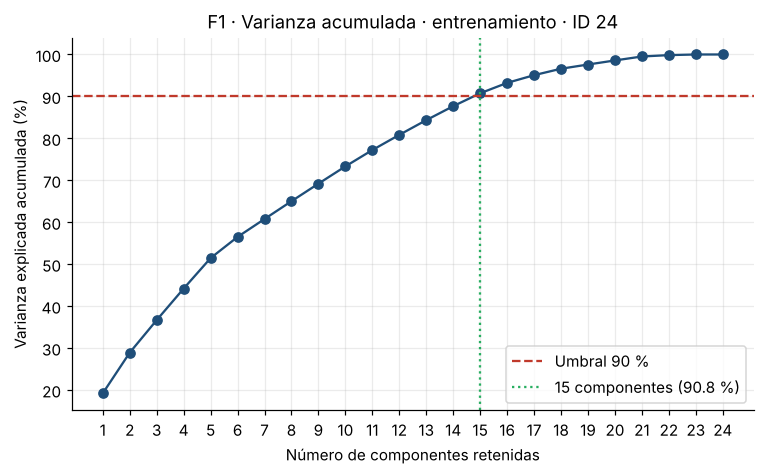

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.4))
x = np.arange(1, len(varianza_acum) + 1)
ax.plot(x, 100 * varianza_acum, marker='o', color='#1f4e79')
ax.axhline(100 * UMBRAL_VARIANZA, color='#c0392b', linestyle='--', label='Umbral 90 %')
ax.axvline(n_componentes, color='#27ae60', linestyle=':',
           label=f'{n_componentes} componentes ({100 * varianza_acum[n_componentes - 1]:.1f} %)')
ax.set_xlabel('Número de componentes retenidas')
ax.set_ylabel('Varianza explicada acumulada (%)')
ax.set_title('F1 · Varianza acumulada · entrenamiento · ID 24')
ax.set_xticks(x); ax.legend(loc='lower right')
mostrar_figura(fig, 'fig_varianza_acumulada')

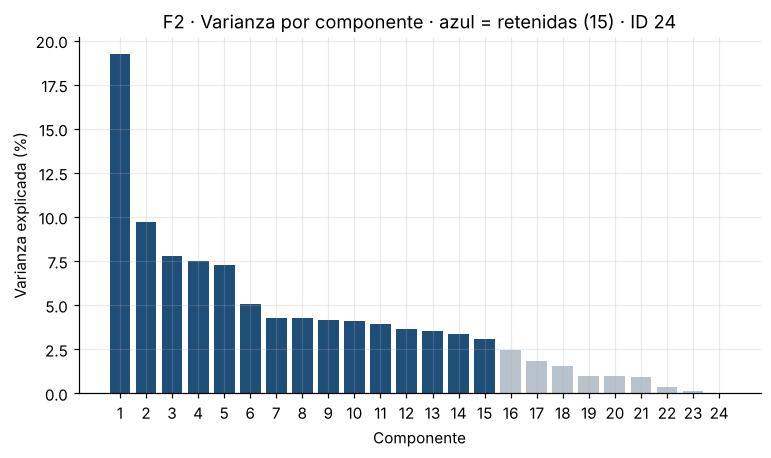

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.2))
colores = ['#1f4e79' if c <= n_componentes else '#b8c2cc' for c in x]
ax.bar(x, 100 * varianza, color=colores)
ax.set_xlabel('Componente'); ax.set_ylabel('Varianza explicada (%)')
ax.set_title(f'F2 · Varianza por componente · azul = retenidas ({n_componentes}) · ID 24')
ax.set_xticks(x)
mostrar_figura(fig, 'fig_varianza_componentes')

In [13]:
# ¿Qué variables pesan en las primeras tres componentes? (lectura descriptiva, no causal)
cargas = pd.DataFrame(pca_completo.components_[:3].T, index=columnas_numericas, columns=['CP1', 'CP2', 'CP3'])
principales = set()
for cp in cargas.columns:
    principales |= set(cargas[cp].abs().nlargest(5).index)
principales = sorted(principales, key=lambda v: -cargas.loc[v].abs().max())
tabla_cargas = cargas.loc[principales].round(3).rename_axis('variable')
mostrar_tabla(tabla_cargas, 'tabla_cargas', 'T2 · Cargas principales de CP1, CP2 y CP3')

**T2 · Cargas principales de CP1, CP2 y CP3**

,CP1,CP2,CP3
variable,,,
vendedor_mismo_estado,-0.061,-0.159,0.497
dias_prometidos,0.082,0.181,-0.474
valor_pagado,0.401,-0.238,-0.071
valor_productos,0.385,-0.278,-0.069
proporcion_flete,-0.154,0.383,-0.132
precio_maximo,0.353,-0.350,-0.105
peso_total_g,0.353,0.221,0.149
vendedor_misma_ciudad,-0.044,-0.106,0.343
valor_flete,0.338,0.293,-0.052


In [14]:
# Pares de variables numéricas más correlacionados (ya estandarizadas, entrenamiento)
corr = pd.DataFrame(X_train_num, columns=columnas_numericas).corr().abs()
pares = corr.where(np.triu(np.ones(corr.shape), k=1) == 1).stack().sort_values(ascending=False).head(6)
tabla_corr = pares.rename('correlacion_abs').reset_index().rename(columns={'level_0': 'variable_1', 'level_1': 'variable_2'})
mostrar_tabla(tabla_corr, 'tabla_correlaciones', 'T3 · Pares numéricos más correlacionados')

**T3 · Pares numéricos más correlacionados**

,variable_1,variable_2,correlacion_abs
0,valor_productos,valor_pagado,0.996
1,valor_productos,precio_maximo,0.945
2,precio_maximo,valor_pagado,0.934
3,peso_total_g,peso_maximo_g,0.886
4,peso_total_g,volumen_total_cm3,0.832
5,dia_semana_compra,compra_fin_semana,0.771


### Interpretación 1. PCA

**Respuesta:** Partí de **24 variables numéricas** y, con el umbral del 90 %, se conservaron **15 componentes**, que explican **90.76 %** de la varianza (con 14 solo se llega a 87.68 %, por eso hacen falta 15). Se descartan 9 componentes, es decir 37.5 % de las dimensiones numéricas, una reducción moderada: la primera componente explica apenas 19.22 % y la segunda 9.70 %, o sea que la varianza está repartida y las variables numéricas son menos redundantes de lo que se esperaría. La redundancia sí existe en grupos concretos: `valor_productos` y `valor_pagado` (|r| = 0.996), `valor_productos` y `precio_maximo` (0.945), `peso_total_g` y `peso_maximo_g` (0.886), `peso_total_g` y `volumen_total_cm3` (0.832).

Lectura descriptiva de las componentes (un peso grande no implica causalidad): CP1 pesa sobre todo en `valor_pagado`, `valor_productos`, `precio_maximo`, `peso_total_g` y `valor_flete` (cargas de 0.34 a 0.40), así que resume el tamaño y valor del pedido; CP2 contrasta `proporcion_flete`, `cantidad_items` y `valor_flete` frente a `precio_maximo`; CP3 reúne `vendedor_mismo_estado` y `vendedor_misma_ciudad` frente a `dias_prometidos`.

**Utilidad y pérdida de información:** PCA resume variables relacionadas y reduce la dimensión numérica, pero se pierde el 9.24 % de la varianza que queda en las 9 componentes descartadas y se pierde la interpretación variable por variable. Además, PCA no mira `is_late`: maximizar varianza no es maximizar capacidad predictiva, y una dirección de poca varianza podría ser justo la que separa entregas tardías de puntuales. Si eso ocurrió se ve en la comparación de modelos (Parte III). Por último, PCA solo reduce la parte numérica: el clasificador recibe 139 columnas con PCA (15 componentes + 124 columnas One-Hot) frente a 148 sin PCA (24 + 124).

## Parte III · Experimentos A a D: ¿mejoran PCA o `C` al modelo?

Los cuatro experimentos usan la misma muestra, la misma partición de validación, el umbral de clasificación 0,50 y `class_weight='balanced'`. Solo cambian la reducción de dimensión y `C`:

| Experimento | Transformación numérica | C |
|---|---|---|
| A · referencia | Sin PCA | 1.0 |
| B · reducción | PCA 90 % | 1.0 |
| C · más penalización | PCA 90 % | 0.1 |
| D · menos penalización | PCA 90 % | 10.0 |

Imputación, escala, PCA y clasificador se ajustan **solo con entrenamiento** dentro de un `Pipeline`; validación solo se transforma.

In [15]:
def construir_modelo(usar_pca, C):
    pasos_num = [SimpleImputer(strategy='median'), StandardScaler()]
    if usar_pca:
        pasos_num.append(PCA(n_components=UMBRAL_VARIANZA, svd_solver='full'))
    preproc = ColumnTransformer([
        ('numericas', make_pipeline(*pasos_num), columnas_numericas),
        ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                      OneHotEncoder(handle_unknown='ignore')),
         columnas_categoricas),
    ])
    return make_pipeline(preproc, LogisticRegression(C=C, class_weight='balanced', max_iter=1000))

EXPERIMENTOS = {
    'A': {'descripcion': 'Referencia: variables numéricas sin PCA', 'pca': False, 'C': 1.0},
    'B': {'descripcion': 'PCA 90 % de varianza', 'pca': True, 'C': 1.0},
    'C': {'descripcion': 'PCA 90 % de varianza, mayor penalización', 'pca': True, 'C': 0.1},
    'D': {'descripcion': 'PCA 90 % de varianza, menor penalización', 'pca': True, 'C': 10.0},
}
UMBRAL_CLASIFICACION = 0.50
COSTO_FP, COSTO_FN = 8, 35   # supuesto didáctico, no costos reales de Olist

modelos, preds, probas, filas = {}, {}, {}, []
for nombre, cfg in EXPERIMENTOS.items():
    m = construir_modelo(cfg['pca'], cfg['C'])
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always')
        m.fit(X_train, y_train)
    convergio = not any(issubclass(a.category, ConvergenceWarning) for a in avisos)

    proba = m.predict_proba(X_valid)[:, 1]
    pred = (proba >= UMBRAL_CLASIFICACION).astype(int)
    assert np.array_equal(pred, m.predict(X_valid))   # mismo umbral 0.50 en los cuatro
    pred_train = (m.predict_proba(X_train)[:, 1] >= UMBRAL_CLASIFICACION).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, pred).ravel()

    ultimo = m[0].named_transformers_['numericas'][-1]
    n_num = getattr(ultimo, 'n_components_', len(columnas_numericas))
    n_cols = m[0].transform(X_valid.iloc[:5]).shape[1]

    modelos[nombre], preds[nombre], probas[nombre] = m, pred, proba
    filas.append({
        'experimento': nombre, 'descripcion': cfg['descripcion'],
        'pca': cfg['pca'], 'C': cfg['C'], 'convergio': convergio,
        'variables_numericas_salida': int(n_num), 'columnas_clasificador': int(n_cols),
        'accuracy': accuracy_score(y_valid, pred),
        'precision': precision_score(y_valid, pred, zero_division=0),
        'recall': recall_score(y_valid, pred, zero_division=0),
        'f1': f1_score(y_valid, pred, zero_division=0),
        'f1_train': f1_score(y_train, pred_train, zero_division=0),
        'roc_auc': roc_auc_score(y_valid, proba),
        'ap': average_precision_score(y_valid, proba),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
        'alertas': int(pred.sum()),
        'costo_brl': float(COSTO_FP * fp + COSTO_FN * fn),
    })

resultados = pd.DataFrame(filas).set_index('experimento')
metricas = ['accuracy', 'precision', 'recall', 'f1', 'ap', 'roc_auc']
assert bool(resultados['convergio'].all()), 'Algún modelo no convergió: revise max_iter.'
display(Markdown(f'Cuatro modelos entrenados y convergidos. Validación: {len(y_valid):,} pedidos, '
                 f'{int(y_valid.sum())} tardíos (prevalencia {y_valid.mean():.3f}).'.replace(',', '.')))

Cuatro modelos entrenados y convergidos. Validación: 5.250 pedidos. 355 tardíos (prevalencia 0.068).

In [16]:
tabla_metricas = resultados[['pca', 'C', 'columnas_clasificador'] + metricas].rename(
    columns={'columnas_clasificador': 'columnas'})
mostrar_tabla(tabla_metricas, 'tabla_metricas', 'T4 · Métricas en validación (umbral 0.50)',
              dec={'C': 1}, maximo=metricas)

**T4 · Métricas en validación (umbral 0.50)**

,pca,C,columnas,accuracy,precision,recall,f1,ap,roc_auc
experimento,,,,,,,,,
A,False,1.0,148,0.667,0.126,0.665,0.213,0.155,0.712
B,True,1.0,139,0.646,0.114,0.628,0.193,0.125,0.680
C,True,0.1,139,0.646,0.115,0.637,0.196,0.127,0.689
D,True,10.0,139,0.646,0.115,0.631,0.194,0.125,0.678


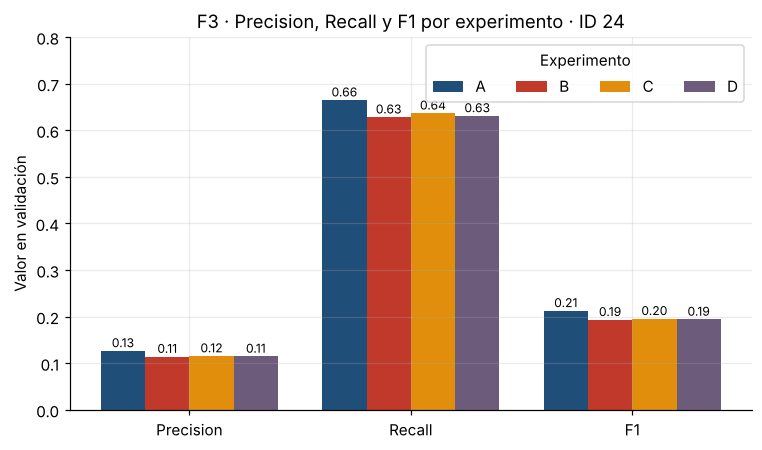

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.4))
etiquetas = ['Precision', 'Recall', 'F1']
ancho = 0.2
for i, n in enumerate(resultados.index):
    valores = [resultados.loc[n, k] for k in ['precision', 'recall', 'f1']]
    barras = ax.bar(np.arange(3) + (i - 1.5) * ancho, valores, ancho, label=n, color=COLORES[n])
    for b, v in zip(barras, valores):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.008, f'{v:.2f}', ha='center', fontsize=8)
ax.set_xticks(range(3)); ax.set_xticklabels(etiquetas)
ax.set_ylim(0, 0.8); ax.set_ylabel('Valor en validación')
ax.set_title('F3 · Precision, Recall y F1 por experimento · ID 24')
ax.legend(title='Experimento', ncol=4, loc='upper right')
mostrar_figura(fig, 'fig_precision_recall_f1')

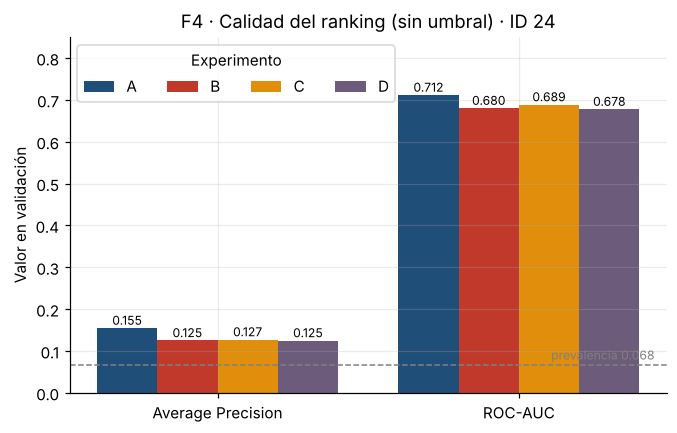

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for i, n in enumerate(resultados.index):
    valores = [resultados.loc[n, 'ap'], resultados.loc[n, 'roc_auc']]
    barras = ax.bar(np.arange(2) + (i - 1.5) * ancho, valores, ancho, label=n, color=COLORES[n])
    for b, v in zip(barras, valores):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.008, f'{v:.3f}', ha='center', fontsize=8)
ax.axhline(y_valid.mean(), color='gray', linestyle='--', linewidth=1)
ax.text(1.45, y_valid.mean() + 0.012, f'prevalencia {y_valid.mean():.3f}', ha='right', fontsize=8, color='gray')
ax.set_xticks(range(2)); ax.set_xticklabels(['Average Precision', 'ROC-AUC'])
ax.set_ylim(0, 0.85); ax.set_ylabel('Valor en validación')
ax.set_title('F4 · Calidad del ranking (sin umbral) · ID 24')
ax.legend(title='Experimento', ncol=4, loc='upper left')
mostrar_figura(fig, 'fig_ap_roc_auc')

In [19]:
dif = (resultados.loc[['B', 'C', 'D'], metricas] - resultados.loc['A', metricas])
tabla_dif = dif.rename_axis('experimento')
mostrar_tabla(tabla_dif, 'tabla_dif_vs_A', 'T5 · Diferencia de cada experimento frente a A (negativo = peor)',
              minimo=metricas)

**T5 · Diferencia de cada experimento frente a A (negativo = peor)**

,accuracy,precision,recall,f1,ap,roc_auc
experimento,,,,,,
B,-0.021,-0.012,-0.037,-0.019,-0.030,-0.031
C,-0.021,-0.011,-0.028,-0.017,-0.027,-0.023
D,-0.021,-0.012,-0.034,-0.018,-0.030,-0.034


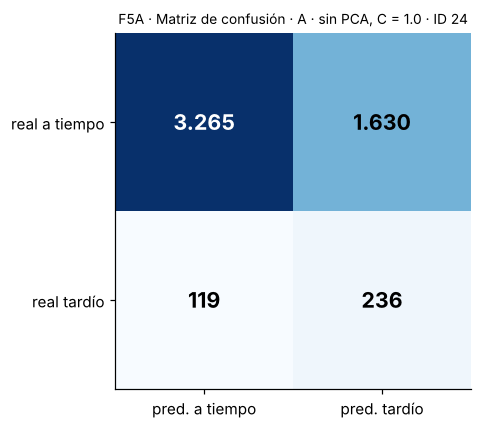

In [20]:
def graficar_confusion(nombre):
    r = resultados.loc[nombre]
    matriz = np.array([[r.tn, r.fp], [r.fn, r.tp]])
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    ax.imshow(matriz, cmap='Blues'); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{int(matriz[i, j]):,}'.replace(',', '.'), ha='center', va='center',
                    fontsize=14, weight='bold', color='white' if matriz[i, j] > matriz.max() / 2 else 'black')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['pred. a tiempo', 'pred. tardío'])
    ax.set_yticks([0, 1]); ax.set_yticklabels(['real a tiempo', 'real tardío'])
    etiqueta = f"{nombre} · {'PCA' if r.pca else 'sin PCA'}, C = {r.C}"
    ax.set_title(f'F5{nombre} · Matriz de confusión · {etiqueta} · ID 24', fontsize=9)
    mostrar_figura(fig, f'fig_confusion_{nombre}')

graficar_confusion('A')

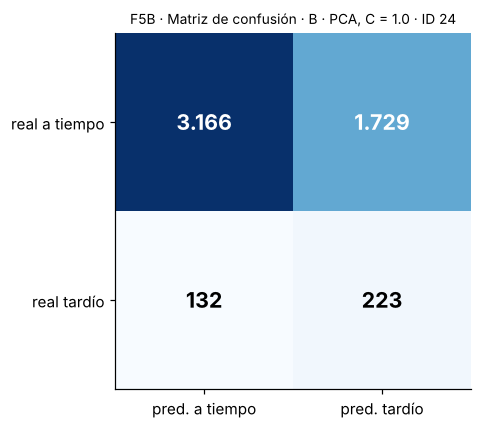

In [21]:
graficar_confusion('B')

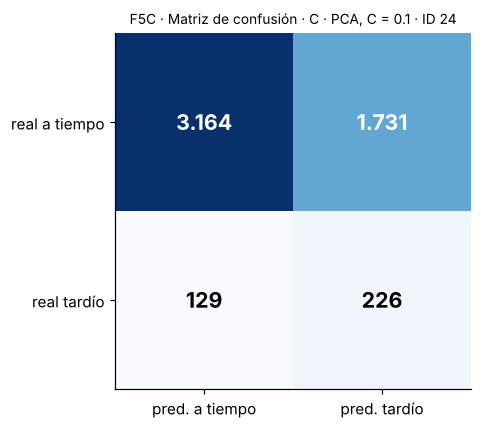

In [22]:
graficar_confusion('C')

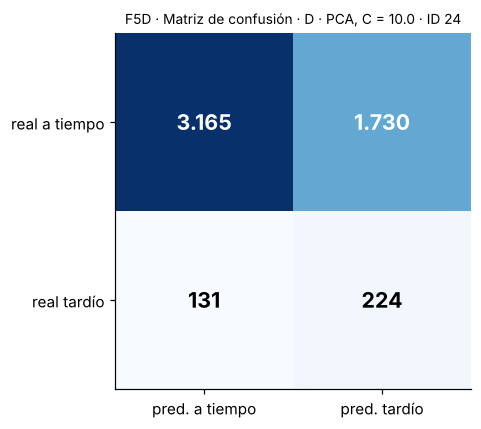

In [23]:
graficar_confusion('D')

In [24]:
sobreajuste = resultados[['f1_train', 'f1']].rename(columns={'f1': 'f1_validacion'})
sobreajuste['brecha'] = sobreajuste['f1_train'] - sobreajuste['f1_validacion']
tabla_sobre = sobreajuste.rename_axis('experimento')
mostrar_tabla(tabla_sobre, 'tabla_sobreajuste', 'T6 · F1 en entrenamiento y validación (¿sobreajuste?)', dec={'brecha': 4})

**T6 · F1 en entrenamiento y validación (¿sobreajuste?)**

,f1_train,f1_validacion,brecha
experimento,,,
A,0.220,0.213,0.0075
B,0.203,0.193,0.0097
C,0.202,0.196,0.0066
D,0.203,0.194,0.0089


### Interpretación 2. Sin PCA frente a PCA, y efecto de `C`

**Respuesta:** El modelo **A (sin PCA, C = 1.0) quedó por encima de B, C y D en todas las métricas**: Accuracy 0.667, Precision 0.126, Recall 0.665, F1 0.213, Average Precision 0.155 y ROC-AUC 0.712.

**Efecto de PCA (B frente a A, mismo C = 1.0):** todas las métricas bajan. El Recall pasa de 0.665 a 0.628 (223 de 355 tardíos detectados en lugar de 236, es decir 13 retrasos más sin detectar), el F1 de 0.213 a 0.193, la AP de 0.155 a 0.125 y el ROC-AUC de 0.712 a 0.680. Como AP y ROC-AUC no dependen del umbral de 0.50, el ordenamiento de los pedidos por riesgo también empeoró, no solo el punto de corte. Mi lectura, que es una inferencia y no algo que probé, es que las 9 componentes descartadas (9.24 % de la varianza) contenían algo de información útil para distinguir entregas tardías. La reducción de 24 a 15 variables numéricas no se tradujo en un modelo mejor.

**Efecto de la regularización (C y D frente a B):** las diferencias son pequeñas. Con C = 0.1 el Recall es 0.637 (226 tardíos detectados), el F1 0.196 y la AP 0.127; con C = 10.0 el Recall es 0.631 (224) y la AP 0.125; con C = 1.0 (B) son 0.628 (223) y 0.125. La mayor penalización (C = 0.1) es la que queda un poco mejor entre los tres modelos con PCA, también en ROC-AUC (0.689 frente a 0.680 y 0.678), pero la ventaja sobre B es de 3 pedidos tardíos detectados y ninguno de los tres alcanza a A. Por eso **no afirmo que C = 0.1 sea realmente mejor que C = 1.0 o C = 10.0**: con una sola partición esa diferencia es demasiado pequeña para sostenerlo.

**Sobreajuste:** el F1 en entrenamiento y en validación es casi igual en los cuatro modelos (A: 0.220 y 0.213; B: 0.203 y 0.193; C: 0.202 y 0.196; D: 0.203 y 0.194; brecha menor a 0.010 en todos). No hay sobreajuste que la regularización tenga que corregir, lo que explica que cambiar `C` casi no mueva los resultados. El límite del modelo no parece ser que memorice, sino su capacidad para separar las clases (AP de 0.125 a 0.155 frente a una prevalencia de 0.068).

**Limitaciones:** todo se midió en una sola partición de validación y no se aplicó ninguna prueba estadística de comparación entre modelos, de modo que las diferencias son observaciones sobre esta muestra, no evidencia de superioridad estadística.

## Parte IV · Costos: ¿cuánto cuestan los errores y qué modelo elijo?

Se retoma el supuesto de la semana 12: **R$ 8 por falso positivo** y **R$ 35 por falso negativo** (cifras didácticas, no costos observados de Olist). Costo = 8·FP + 35·FN. Se incluyen dos referencias triviales: nunca alertar y alertar todos los pedidos.

In [25]:
referencia = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)
_, fp_r, fn_r, _ = confusion_matrix(y_valid, pred_ref).ravel()
costo_referencia = COSTO_FP * fp_r + COSTO_FN * fn_r                 # nunca alertar
n_a_tiempo = int((y_valid == 0).sum())
costo_alertar_todo = COSTO_FP * n_a_tiempo                            # alertar los 5.250 pedidos
precision_equilibrio = COSTO_FP / (COSTO_FP + COSTO_FN)

filas_costo = []
for n in resultados.index:
    r = resultados.loc[n]
    filas_costo.append([n, int(r.fp), int(r.fn), int(COSTO_FP * r.fp), int(COSTO_FN * r.fn),
                        int(r.costo_brl), float(r.precision), int(r.costo_brl - costo_referencia)])
filas_costo.append(['nunca alertar', int(fp_r), int(fn_r), int(COSTO_FP * fp_r), int(COSTO_FN * fn_r),
                    int(costo_referencia), None, 0])
filas_costo.append(['alertar todos', n_a_tiempo, 0, int(costo_alertar_todo), 0, int(costo_alertar_todo),
                    float(y_valid.mean()), int(costo_alertar_todo - costo_referencia)])
tabla_costos = pd.DataFrame(filas_costo, columns=['modelo', 'FP', 'FN', 'costo_FP_brl', 'costo_FN_brl',
                                                  'costo_total_brl', 'precision', 'vs_nunca_alertar_brl'])
assert np.allclose(tabla_costos.loc[:3, 'costo_total_brl'], resultados['costo_brl'])
mejor = tabla_costos.loc[:3].set_index('modelo')['costo_total_brl'].idxmin()
display(Markdown(f'Punto de equilibrio: alertar compensa solo si la precisión supera 8 / (8 + 35) = **{precision_equilibrio:.3f}**. '
                 f'El modelo de menor costo entre A–D es **{mejor}**.'))
mostrar_tabla(tabla_costos, 'tabla_costos', 'T7 · Errores y costo didáctico en validación (R$)')

Punto de equilibrio: alertar compensa solo si la precisión supera 8 / (8 + 35) = **0.186**. El modelo de menor costo entre A–D es **A**.

**T7 · Errores y costo didáctico en validación (R$)**

,modelo,FP,FN,costo_FP_brl,costo_FN_brl,costo_total_brl,precision,vs_nunca_alertar_brl
0,A,1.630,119,13.040,4.165,17.205,0.126,4.780
1,B,1.729,132,13.832,4.620,18.452,0.114,6.027
2,C,1.731,129,13.848,4.515,18.363,0.115,5.938
3,D,1.730,131,13.840,4.585,18.425,0.115,6.000
4,nunca alertar,0,355,0,12.425,12.425,nan,0
5,alertar todos,4.895,0,39.160,0,39.160,0.068,26.735


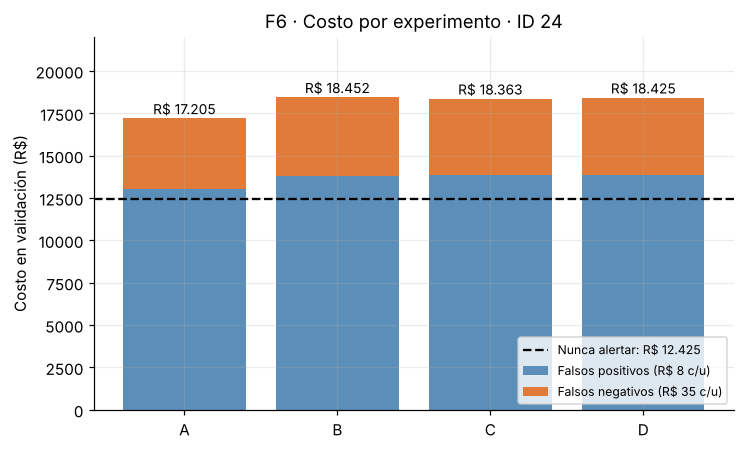

In [26]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
nombres = list(resultados.index)
fp_brl = [COSTO_FP * resultados.loc[n, 'fp'] for n in nombres]
fn_brl = [COSTO_FN * resultados.loc[n, 'fn'] for n in nombres]
ax.bar(nombres, fp_brl, color='#5b8fb9', label='Falsos positivos (R$ 8 c/u)')
ax.bar(nombres, fn_brl, bottom=fp_brl, color='#e07b39', label='Falsos negativos (R$ 35 c/u)')
for i, (a, b) in enumerate(zip(fp_brl, fn_brl)):
    ax.text(i, a + b + 250, f'R$ {int(a + b):,}'.replace(',', '.'), ha='center', fontsize=9)
ax.axhline(costo_referencia, color='black', linestyle='--', label=f'Nunca alertar: R$ {int(costo_referencia):,}'.replace(',', '.'))
ax.set_ylim(0, 22000); ax.set_ylabel('Costo en validación (R$)')
ax.set_title('F6 · Costo por experimento · ID 24')
ax.legend(fontsize=8, loc='lower right')
mostrar_figura(fig, 'fig_costos')

### Interpretación 3. Elección del modelo y decisión empresarial

**Respuesta:** Los costos en validación son: **A = R$ 17.205** (1.630 FP = R$ 13.040 y 119 FN = R$ 4.165), **B = R$ 18.452** (1.729 FP y 132 FN), **C = R$ 18.363** (1.731 FP y 129 FN) y **D = R$ 18.425** (1.730 FP y 131 FN). Pasar de A a B con PCA añade R$ 1.247 (+7.2 %): 99 falsas alarmas más y 13 retrasos más sin detectar. C y D cuestan R$ 89 y R$ 27 menos que B, es decir, la regularización casi no cambia el costo.

**Elección entre A–D: modelo A.** En esta comparación los tres criterios de la pregunta de análisis coinciden: A tiene la mayor Accuracy (0.667), el mayor Recall (0.665) y el menor costo, así que dentro de A–D no hay conflicto entre «más aciertos», «más tardíos identificados» y «menor costo». Además es el más simple, y ni PCA ni modificar `C` aportaron mejora.

**Pero el conflicto aparece frente a la referencia trivial.** El modelo que siempre predice «a tiempo» tiene Accuracy 0.932 (la más alta), Recall 0 y un costo de **R$ 12.425** (355 FN × R$ 35), menor que el de cualquiera de las cuatro configuraciones. A cuesta R$ 4.780 más (+38.5 %). Alertar todos los pedidos costaría R$ 39.160, de modo que los cuatro modelos son mucho mejores que eso, pero ninguno mejora a no alertar. La razón es que, con estos costos, alertar un pedido solo compensa si la probabilidad de que sea tardío supera 8 / (8 + 35) ≈ 18.6 %, y la precisión de A es 12.6 %: de 1.866 alertas, solo 236 eran retrasos reales.

**Decisión:** entre las cuatro alternativas elijo A, pero con el umbral de 0.50 y estos costos supuestos **no recomendaría poner el modelo en operación**: cada alerta tendría que acertar al menos 18.6 % de las veces para compensar. Una vía de mejora sería evaluar otro umbral o más información predictiva (como la propuesta de ruta y vendedor de la semana 12), tratándolo como un experimento aparte en validación y sin tocar la prueba reservada.

**Limitaciones:** los costos son supuestos didácticos (no incluyen el costo fijo de operar alertas ni el costo de intervenir un pedido bien detectado), el resultado depende de una sola partición de validación y las diferencias pequeñas entre B, C y D no son concluyentes.

## Parte V · Prueba de Kolmogorov-Smirnov sobre `valor_flete`

**Hipótesis (α = 0,05):**

- H0: `valor_flete` tiene la misma distribución en entrenamiento y en validación.
- H1: las distribuciones de `valor_flete` en entrenamiento y validación son diferentes (prueba bilateral).

La prueba compara las distribuciones de una variable; **no compara el desempeño de los modelos**.

In [27]:
ALFA = 0.05
flete_train = train['valor_flete'].dropna()
flete_valid = valid['valor_flete'].dropna()

resultado_ks = ks_2samp(flete_train, flete_valid, alternative='two-sided')
D, p = float(resultado_ks.statistic), float(resultado_ks.pvalue)
decision = 'Rechazar H0' if p < ALFA else 'No rechazar H0'

tabla_ks = pd.DataFrame({
    'n_entrenamiento': [len(flete_train)], 'n_validacion': [len(flete_valid)],
    'estadistico_D': [D], 'valor_p': [p], 'alfa': [ALFA], 'decision': [decision]})
mostrar_tabla(tabla_ks, 'tabla_ks', 'T8 · Resultado de la prueba KS sobre valor_flete',
              dec={'estadistico_D': 4, 'valor_p': 4, 'alfa': 2})

**T8 · Resultado de la prueba KS sobre valor_flete**

,n_entrenamiento,n_validacion,estadistico_D,valor_p,alfa,decision
0,24.500,5.250,0.0122,0.5331,0.05,No rechazar H0


In [28]:
descr = pd.DataFrame({
    'entrenamiento': flete_train.describe(percentiles=[.25, .5, .75]),
    'validación': flete_valid.describe(percentiles=[.25, .5, .75]),
})
# Texto ya formateado: estadísticas con 2 decimales y conteos como enteros
tabla_descr = descr.map(lambda v: f'{v:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.'))
tabla_descr.loc['count'] = [f'{len(flete_train):,}'.replace(',', '.'), f'{len(flete_valid):,}'.replace(',', '.')]
tabla_descr.loc['valores_distintos'] = [f'{flete_train.nunique():,}'.replace(',', '.'), f'{flete_valid.nunique():,}'.replace(',', '.')]
tabla_descr.loc['flete_igual_a_0'] = [int((flete_train == 0).sum()), int((flete_valid == 0).sum())]
tabla_descr = tabla_descr.astype(str).rename_axis('estadístico')
mostrar_tabla(tabla_descr, 'tabla_descr_flete', 'T9 · valor_flete: descriptivas y empates por partición')

**T9 · valor_flete: descriptivas y empates por partición**

,entrenamiento,validación
estadístico,,
count,24.500,5.250
mean,"22,72","22,56"
std,"20,41","20,69"
min,"0,00","0,00"
25%,"13,79","13,92"
50%,"17,09","17,27"
75%,"24,04","23,75"
max,"502,98","626,64"
valores_distintos,4.645,2.126


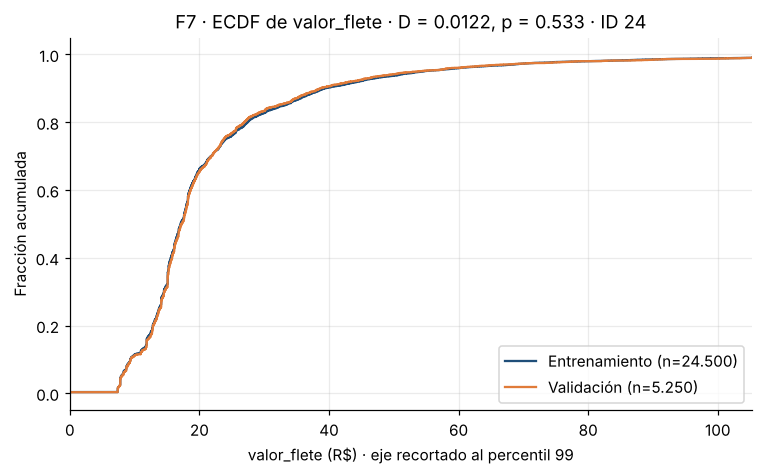

In [29]:
def ecdf(valores):
    v = np.sort(np.asarray(valores))
    return v, np.arange(1, len(v) + 1) / len(v)

fig, ax = plt.subplots(figsize=(8, 4.4))
for datos, etiqueta, color in [(flete_train, 'Entrenamiento', '#1f4e79'), (flete_valid, 'Validación', '#e07b39')]:
    xs, ys = ecdf(datos)
    ax.step(xs, ys, where='post', label=f'{etiqueta} (n={len(datos):,})'.replace(',', '.'), color=color)
ax.set_xlim(0, float(np.percentile(pd.concat([flete_train, flete_valid]), 99)))
ax.set_xlabel('valor_flete (R$) · eje recortado al percentil 99')
ax.set_ylabel('Fracción acumulada')
ax.set_title(f'F7 · ECDF de valor_flete · D = {D:.4f}, p = {p:.3f} · ID 24')
ax.legend()
mostrar_figura(fig, 'fig_ecdf_flete')

### Interpretación 4. Prueba KS

**Respuesta:** Se compararon 24.500 pedidos de entrenamiento con 5.250 de validación. El estadístico fue **D = 0.0122** (la separación vertical máxima entre las dos ECDF) y el **valor p = 0.533**. Como p ≥ 0.05, **no se rechaza H0** al 5 %: no hay evidencia suficiente de que la distribución de `valor_flete` difiera entre ambas particiones. Esto es coherente con las medidas descriptivas: mediana 17.09 frente a 17.28, primer cuartil 13.79 frente a 13.92 y tercer cuartil 24.04 frente a 23.75, y con que la partición fue aleatoria y estratificada por `is_late`.

**Qué no significa:** no rechazar H0 no demuestra que las distribuciones sean idénticas, ni que el modelo esté validado, ni que una configuración sea mejor que otra; la prueba solo mira una variable (de las 28) y no usa predicciones.

**Limitación metodológica:** la prueba KS clásica se formula para variables continuas, y `valor_flete` tiene muchos valores repetidos (importes en centavos): solo hay 4.645 valores distintos en los 24.500 pedidos de entrenamiento y 2.126 en los 5.250 de validación, además de 88 y 17 pedidos con flete igual a 0. Con tantos empates el valor p debe leerse con cautela. Además, el valor p no mide la magnitud de la diferencia (para eso sirven D, la gráfica y los cuartiles) y una partición aleatoria no garantiza que los pedidos futuros se comporten igual.

## Parte VI · Conclusión

**Pregunta de análisis: ¿más aciertos, más entregas tardías identificadas o menor costo?** Entre las cuatro configuraciones la respuesta no se divide: el modelo A (sin PCA, C = 1.0) tiene la mayor Accuracy (0.667), el mayor Recall (0.665) y el menor costo (R$ 17.205). El conflicto aparece solo frente al modelo que siempre predice «a tiempo»: tiene la mayor Accuracy (0.932) y el menor costo (R$ 12.425), pero no detecta ningún retraso. Por eso Accuracy sola no sirve en este problema, y el criterio que decide es el costo de los errores junto con el Recall.

**Qué aprendí con mi muestra (ID 24):**

1. Reducir de 24 a 15 variables numéricas con PCA no mejoró nada; empeoró Recall, F1, AP y costo. Resumir varianza no es lo mismo que conservar capacidad predictiva.
2. Cambiar `C` entre 0.1 y 10 movió muy poco los resultados (C = 0.1 quedó apenas mejor que los otros dos con PCA, por 3 pedidos tardíos), y el F1 de entrenamiento y validación es casi igual: el problema no es sobreajuste.
3. El KS no encontró diferencia entre las distribuciones de `valor_flete` de entrenamiento y validación (p = 0.533), con la cautela por los valores repetidos; no dice nada sobre cuál modelo es mejor.
4. Con el umbral de 0.50 y los costos supuestos, ninguno de los cuatro modelos justifica operar como sistema automático de alertas: la precisión (0.126) está por debajo del punto de equilibrio (0.186).

**Hechos y supuestos:** son hechos observados las métricas, los FP, los FN y los costos en validación. Son supuestos los costos de R$ 8 y R$ 35, el umbral de 0.50 y que esta validación represente pedidos futuros. Las lecturas sobre por qué PCA empeoró el modelo son inferencias, no pruebas.

**Siguiente paso (no ejecutado aquí):** tratar como experimento aparte un cambio del umbral o variables nuevas (por ejemplo la ruta entre el estado del vendedor y el del cliente, propuesta en la semana 12), evaluado en validación y sin tocar la prueba final, que sigue reservada.

## Parte VII · Cierre técnico

Comprobaciones de reproducibilidad, y registro de todo lo generado en `reports/`.

In [30]:
assert len(muestra) == 35000 and (len(train), len(valid), len(test)) == (24500, 5250, 5250)
assert set(train['order_id']).isdisjoint(valid['order_id'])
assert set(train['order_id']).isdisjoint(test['order_id'])
assert set(valid['order_id']).isdisjoint(test['order_id'])
assert ID_ESTUDIANTE == 24 and semilla == 1024 and huella_muestra == '89a094b75572'

assert n_componentes == int(modelos['B'][0].named_transformers_['numericas'][-1].n_components_)
assert varianza_acum[n_componentes - 1] >= UMBRAL_VARIANZA > varianza_acum[n_componentes - 2]

assert list(resultados.index) == ['A', 'B', 'C', 'D']
assert all(len(p_) == len(y_valid) for p_ in preds.values())
assert all(m_[-1].class_weight == 'balanced' for m_ in modelos.values())
assert [m_[-1].C for m_ in modelos.values()] == [1.0, 1.0, 0.1, 10.0]
for nombre in resultados.index:
    r = resultados.loc[nombre]
    assert np.isclose(r['costo_brl'], 8 * r['fp'] + 35 * r['fn'])
    assert r['tn'] + r['fp'] + r['fn'] + r['tp'] == len(y_valid)
assert 0 <= D <= 1 and 0 <= p <= 1
assert all(Path(f).exists() for f in ARCHIVOS), 'Falta algún archivo de tablas o figuras.'
display(Markdown(f'Autoverificación superada. Se guardaron **{len(ARCHIVOS)}** archivos individuales de tablas y figuras.'))

Autoverificación superada. Se guardaron **28** archivos individuales de tablas y figuras.

In [31]:
# --- Bitácora de experimentos (una fila por configuración) ---
bitacora = resultados.reset_index().copy()
bitacora.insert(0, 'laboratorio', 'S14')
bitacora.insert(1, 'id_estudiante', identificador)
bitacora.insert(2, 'semilla', semilla)
bitacora.insert(3, 'huella_muestra', huella_muestra)
bitacora['preprocesamiento'] = np.where(
    bitacora['pca'], 'mediana+StandardScaler+PCA(90%) | moda+OneHot', 'mediana+StandardScaler | moda+OneHot')
bitacora['class_weight'] = 'balanced'
bitacora['umbral'] = UMBRAL_CLASIFICACION
ruta_csv = REPORTES / f'S14_bitacora_experimentos_{SUFIJO}.csv'
bitacora.round(6).to_csv(ruta_csv, index=False)

# --- Reporte JSON ---
reporte = {
    'laboratorio': 'S14', 'id_estudiante': identificador, 'semilla': semilla,
    'timestamp_utc': pd.Timestamp.now('UTC').isoformat(),
    'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__,
    'sklearn': sklearn.__version__, 'scipy': scipy.__version__,
    'n_muestra': len(muestra), 'n_train': len(train), 'n_valid': len(valid), 'n_test': len(test),
    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf',
    'huella_muestra': huella_muestra,
    'umbral_clasificacion': UMBRAL_CLASIFICACION,
    'costos_supuestos_brl': {'falso_positivo': COSTO_FP, 'falso_negativo': COSTO_FN},
    'pca': {
        'variables_numericas_iniciales': len(columnas_numericas), 'umbral_varianza': UMBRAL_VARIANZA,
        'componentes_retenidas': n_componentes,
        'varianza_acumulada_retenida': float(varianza_acum[n_componentes - 1]),
        'varianza_primera_componente': float(varianza[0]),
    },
    'experimentos': {
        nombre: {
            'descripcion': EXPERIMENTOS[nombre]['descripcion'],
            'usa_pca': bool(EXPERIMENTOS[nombre]['pca']), 'C': EXPERIMENTOS[nombre]['C'],
            'columnas_clasificador': int(resultados.loc[nombre, 'columnas_clasificador']),
            'metricas_validacion': {k: float(resultados.loc[nombre, k]) for k in metricas},
            'f1_entrenamiento': float(resultados.loc[nombre, 'f1_train']),
            'fp': int(resultados.loc[nombre, 'fp']), 'fn': int(resultados.loc[nombre, 'fn']),
            'costo_brl': float(resultados.loc[nombre, 'costo_brl']),
        } for nombre in resultados.index
    },
    'referencia_siempre_a_tiempo': {'accuracy': float(accuracy_score(y_valid, pred_ref)),
                                    'fn': int(fn_r), 'costo_brl': float(costo_referencia)},
    'referencia_alertar_todo': {'costo_brl': float(costo_alertar_todo)},
    'modelo_elegido': mejor,
    'ks_valor_flete': {'n_train': int(len(flete_train)), 'n_valid': int(len(flete_valid)),
                       'estadistico_D': D, 'valor_p': p, 'alfa': ALFA, 'decision': decision},
}
ruta_json = REPORTES / f'S14_reporte_{SUFIJO}.json'
ruta_json.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')

# --- Resumen del análisis (Markdown, con tablas y gráficas enlazadas) ---
fila = lambda n: resultados.loc[n]
miles = lambda v: f'{int(v):,}'.replace(',', '.')
tabla_md = '\n'.join(
    f"| {n} | {'Sí' if EXPERIMENTOS[n]['pca'] else 'No'} | {EXPERIMENTOS[n]['C']} | "
    f"{fila(n)['accuracy']:.3f} | {fila(n)['precision']:.3f} | {fila(n)['recall']:.3f} | "
    f"{fila(n)['f1']:.3f} | {fila(n)['ap']:.3f} | {miles(fila(n)['fp'])} | {int(fila(n)['fn'])} | "
    f"R$ {miles(fila(n)['costo_brl'])} |" for n in resultados.index)
resumen = f"""# Resumen S14 · ID {identificador} · PCA y evaluación de mejoras

Muestra de {len(muestra):,} pedidos (huella `{huella_muestra}`); validación de {len(valid):,} pedidos con {int(y_valid.sum())} tardíos.
Umbral 0.50 y `class_weight='balanced'` en todos los modelos. La prueba final no se usó.

## 1. PCA
{len(columnas_numericas)} variables numéricas -> **{n_componentes} componentes** ({100 * varianza_acum[n_componentes - 1]:.2f} % de varianza).
El clasificador recibe {int(fila('B')['columnas_clasificador'])} columnas con PCA y {int(fila('A')['columnas_clasificador'])} sin PCA.

![F1](figuras/S14_fig_varianza_acumulada_{SUFIJO}.png)

## 2. Experimentos en validación
| Exp. | PCA | C | Accuracy | Precision | Recall | F1 | AP | FP | FN | Costo |
|---|---|---|---|---|---|---|---|---|---|---|
{tabla_md}

![F3](figuras/S14_fig_precision_recall_f1_{SUFIJO}.png)

F1 en entrenamiento y validación: brecha máxima {(resultados['f1_train'] - resultados['f1']).max():.3f} (sin señal de sobreajuste).

## 3. Costo
Nunca alertar: R$ {miles(costo_referencia)}. Alertar todos: R$ {miles(costo_alertar_todo)}.
Punto de equilibrio de precisión: {precision_equilibrio:.3f}; precisión de A: {fila('A')['precision']:.3f}.

![F6](figuras/S14_fig_costos_{SUFIJO}.png)

## 4. KS sobre `valor_flete`
D = {D:.4f}, p = {p:.3f} -> {decision} al 5 %. No demuestra que las distribuciones sean idénticas; hay muchos empates en los importes.

![F7](figuras/S14_fig_ecdf_flete_{SUFIJO}.png)

## 5. Decisión
- Modelo elegido entre A–D: **{mejor}** (menor costo y mejor en todas las métricas).
- PCA empeoró Recall, F1, AP y costo; cambiar C modificó muy poco los resultados.
- Ninguna configuración supera en costo a nunca alertar con los costos supuestos: no se recomienda operar con umbral 0.50.
- Limitaciones: costos supuestos, una sola partición de validación, sin pruebas de comparación entre modelos.
"""
(REPORTES / f'S14_resumen_analisis_{SUFIJO}.md').write_text(resumen, encoding='utf-8')

ARCHIVOS.extend([ruta_csv, ruta_json, REPORTES / f'S14_resumen_analisis_{SUFIJO}.md'])
inventario = pd.DataFrame({
    'carpeta': [str(f.parent.name) for f in ARCHIVOS],
    'archivo': [f.name for f in ARCHIVOS],
}).sort_values(['carpeta', 'archivo']).reset_index(drop=True)
display(Markdown(f'**Archivos generados en `reports/` ({len(inventario)}):**'))
display(inventario)

# En Colab, descarga todo en un único zip para conservarlo fuera de la sesión.
try:
    from google.colab import files
    shutil.make_archive(f'reports_{SUFIJO}', 'zip', REPORTES)
    files.download(f'reports_{SUFIJO}.zip')
except Exception:
    print('Si no se descargó automáticamente, guarde manualmente la carpeta reports/.')

**Archivos generados en `reports/` (31):**

,carpeta,archivo
0,figuras,S14_fig_varianza_acumulada_ID_24.png
1,figuras,S14_fig_varianza_componentes_ID_24.png
2,figuras,S14_fig_precision_recall_f1_ID_24.png
3,figuras,S14_fig_ap_roc_auc_ID_24.png
4,figuras,S14_fig_confusion_A_ID_24.png
5,figuras,S14_fig_confusion_B_ID_24.png
6,figuras,S14_fig_confusion_C_ID_24.png
7,figuras,S14_fig_confusion_D_ID_24.png
8,figuras,S14_fig_costos_ID_24.png
9,figuras,S14_fig_ecdf_flete_ID_24.png


Si no se descargó automáticamente, guarde manualmente la carpeta reports/.
